# Notebook 8 — Auditoria de Equidade Algorítmica

**TCC — Predição de evasão no ensino superior** · Curso de Sistemas de Informação — UEMG

---

## Por que esta auditoria é obrigatória

A Fase 5 confirmou que o modelo **usa** atributos sensíveis: gênero aparece entre os fatores ativos
(ρ = +0,55 na direção de risco), e variáveis socioeconômicas — bolsa, inadimplência, ocupação dos pais
— estão entre os preditores relevantes.

Isso, por si só, não é problema. O problema seria o modelo **errar mais para algum subgrupo**. E a razão
é específica ao produto deste trabalho:

> O sistema não gera uma nota acadêmica nem uma estatística. Ele gera uma **lista de alunos que
> receberão apoio institucional**. Se o modelo detecta pior um subgrupo, esse subgrupo é sinalizado
> menos, recebe menos apoio, e o sistema **amplifica a desigualdade que deveria combater**.

A limitação [L-11](07-limitacoes-e-trabalhos-futuros.md) registrava essa lacuna como "a mais importante
entre as não previstas no escopo original". Este notebook a fecha.

## O que se mede

| Métrica | Pergunta que responde |
|---|---|
| **Recall** por subgrupo | Dos alunos deste grupo que evadiram, quantos o modelo detectou? |
| **Taxa de falsos negativos** (FNR = 1 − recall) | Quantos evadidos deste grupo passaram sem alerta? |
| **Taxa de falsos positivos** (FPR) | Quantos concluintes deste grupo foram convocados sem necessidade? |
| **Precisão** por subgrupo | Dos sinalizados deste grupo, quantos realmente evadiram? |

**Paridade de recall** exige recall semelhante entre subgrupos. **Equalized odds** é mais exigente:
requer paridade simultânea de recall **e** de FPR.

> Nada é retreinado. A auditoria usa as predições do `melhor_modelo.joblib` sobre o conjunto de teste
> já existente.

## 1. Configuração e recuperação dos atributos sensíveis

In [1]:
import os
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.metrics import recall_score, precision_score
from statsmodels.stats.proportion import proportion_confint, test_proportions_2indep

warnings.filterwarnings("ignore")
SEED = 42
DIR_DADOS, DIR_FIGURAS, DIR_MODELOS = "dados", "figuras", "modelos"

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold",
})

def salvar(nome):
    caminho = os.path.join(DIR_FIGURAS, nome)
    plt.savefig(caminho)
    print(f"[figura salva] {caminho}")

# --- Predições do modelo final ---------------------------------------------
X_teste = pd.read_csv(os.path.join(DIR_DADOS, "X_test.csv"))
y_teste = pd.read_csv(os.path.join(DIR_DADOS, "y_test.csv"))["target"].to_numpy()
pipeline = joblib.load(os.path.join(DIR_MODELOS, "melhor_modelo.joblib"))
y_pred = pipeline.predict(X_teste)

# --- Atributos sensíveis em escala ORIGINAL --------------------------------
# X_test.csv está padronizado; para segmentar por "idade 21-25" é preciso o valor
# bruto. A partição é reconstruída com a mesma semente — procedimento já validado
# no Notebook 5 e no Notebook 7.
df_limpo = pd.read_csv(os.path.join(DIR_DADOS, "dataset_limpo.csv"))
binario = df_limpo[df_limpo["target"] != "Enrolled"].reset_index(drop=True)
X_todo = binario.drop(columns=["target"])
y_todo = (binario["target"] == "Dropout").astype(int)

_, X_bruto, _, y_bruto = train_test_split(
    X_todo, y_todo, test_size=0.20, random_state=SEED, stratify=y_todo)
X_bruto = X_bruto.reset_index(drop=True)

assert list(y_bruto) == list(y_teste), "A partição reconstruída não corresponde ao y_test.csv."
print("Partição reconstruída confere com o conjunto de teste salvo.")
print(f"Teste: {len(y_teste)} alunos, {int(y_teste.sum())} evadidos ({y_teste.mean():.1%})")

Partição reconstruída confere com o conjunto de teste salvo.
Teste: 726 alunos, 284 evadidos (39.1%)


In [2]:
# --- Definição dos subgrupos ------------------------------------------------
# Os cortes de idade seguem a distribuição real: mediana 20, 3º quartil 25.
print("Idade no ingresso — distribuição no teste:")
print(X_bruto["age_at_enrollment"].describe()[["min", "25%", "50%", "75%", "max"]].to_string())

faixa_idade = pd.cut(X_bruto["age_at_enrollment"], bins=[0, 20, 25, 200],
                     labels=["até 20 anos", "21 a 25 anos", "26 anos ou mais"])

SUBGRUPOS = {
    "Gênero": [("feminino (0)", X_bruto["gender"] == 0),
               ("masculino (1)", X_bruto["gender"] == 1)],
    "Faixa etária": [(str(f), faixa_idade == f) for f in faixa_idade.cat.categories],
    "Bolsista": [("não bolsista", X_bruto["scholarship_holder"] == 0),
                 ("bolsista", X_bruto["scholarship_holder"] == 1)],
    "Turno": [("noturno (0)", X_bruto["daytime_evening_attendance"] == 0),
              ("diurno (1)", X_bruto["daytime_evening_attendance"] == 1)],
    "Deslocado da cidade": [("não deslocado", X_bruto["displaced"] == 0),
                            ("deslocado", X_bruto["displaced"] == 1)],
}

print()
print("Composição dos subgrupos:")
for variavel, subs in SUBGRUPOS.items():
    partes = [f"{nome}: {int(m.sum())}" for nome, m in subs]
    print(f"   {variavel:<22} {'  |  '.join(partes)}")

Idade no ingresso — distribuição no teste:
min    17.0
25%    19.0
50%    20.0
75%    25.0
max    70.0

Composição dos subgrupos:
   Gênero                 feminino (0): 438  |  masculino (1): 288
   Faixa etária           até 20 anos: 422  |  21 a 25 anos: 130  |  26 anos ou mais: 174
   Bolsista               não bolsista: 552  |  bolsista: 174
   Turno                  noturno (0): 76  |  diurno (1): 650
   Deslocado da cidade    não deslocado: 323  |  deslocado: 403


## 2. Métricas por subgrupo

Cada subgrupo recebe o **intervalo de confiança de Wilson**. Isso é indispensável aqui: alguns
subgrupos têm poucos evadidos — a base do cálculo do recall — e uma disparidade aparente pode ser
inteiramente ruído amostral.

A comparação entre o subgrupo de maior e o de menor recall é submetida a um **teste de diferença de
proporções**.

In [3]:
def metricas_subgrupo(mascara):
    """Recall, precisão, FNR e FPR com IC de Wilson, para um subgrupo."""
    m = mascara.to_numpy() if hasattr(mascara, "to_numpy") else mascara
    yy, pp = y_teste[m], y_pred[m]
    vp = int(((yy == 1) & (pp == 1)).sum())
    fn = int(((yy == 1) & (pp == 0)).sum())
    fp = int(((yy == 0) & (pp == 1)).sum())
    vn = int(((yy == 0) & (pp == 0)).sum())

    evadidos = vp + fn
    concluintes = fp + vn
    recall = vp / evadidos if evadidos else np.nan
    fpr = fp / concluintes if concluintes else np.nan
    rec_lo, rec_hi = (proportion_confint(vp, evadidos, alpha=0.05, method="wilson")
                      if evadidos else (np.nan, np.nan))
    fpr_lo, fpr_hi = (proportion_confint(fp, concluintes, alpha=0.05, method="wilson")
                      if concluintes else (np.nan, np.nan))
    return {
        "n": int(m.sum()), "evadidos": evadidos, "concluintes": concluintes,
        "taxa-base de evasão": yy.mean(),
        "recall": recall, "recall IC inf": rec_lo, "recall IC sup": rec_hi,
        "FNR": 1 - recall if evadidos else np.nan,
        "precisão": vp / (vp + fp) if (vp + fp) else np.nan,
        "FPR": fpr, "FPR IC inf": fpr_lo, "FPR IC sup": fpr_hi,
        "VP": vp, "FN": fn, "FP": fp, "VN": vn,
    }


linhas = []
for variavel, subs in SUBGRUPOS.items():
    for nome, mascara in subs:
        linhas.append({"variável": variavel, "subgrupo": nome, **metricas_subgrupo(mascara)})

auditoria = pd.DataFrame(linhas)
display(auditoria[["variável", "subgrupo", "n", "evadidos", "taxa-base de evasão",
                   "recall", "recall IC inf", "recall IC sup",
                   "FNR", "FPR", "precisão"]].round(4))

,variável,subgrupo,n,evadidos,taxa-base de evasão,recall,recall IC inf,recall IC sup,FNR,FPR,precisão
0,Gênero,feminino (0),438,130,0.2968,0.8846,0.8183,0.9288,0.1154,0.0422,0.8984
1,Gênero,masculino (1),288,154,0.5347,0.9091,0.8532,0.9451,0.0909,0.0821,0.9272
2,Faixa etária,até 20 anos,422,113,0.2678,0.8584,0.7823,0.9109,0.1416,0.0583,0.8435
3,Faixa etária,21 a 25 anos,130,55,0.4231,0.9091,0.8042,0.9605,0.0909,0.0533,0.9259
4,Faixa etária,26 anos ou mais,174,116,0.6667,0.9310,0.8698,0.9646,0.0690,0.0345,0.9818
5,Bolsista,não bolsista,552,258,0.4674,0.8953,0.8520,0.9271,0.1047,0.0680,0.9203
6,Bolsista,bolsista,174,26,0.1494,0.9231,0.7586,0.9786,0.0769,0.0270,0.8571
7,Turno,noturno (0),76,39,0.5132,0.9231,0.7968,0.9735,0.0769,0.0541,0.9474
8,Turno,diurno (1),650,245,0.3769,0.8939,0.8490,0.9265,0.1061,0.0543,0.9087
9,Deslocado da cidade,não deslocado,323,161,0.4985,0.9130,0.8593,0.9475,0.0870,0.0309,0.9671


In [4]:
# --- Disparidade e significância por variável -------------------------------
resumo = []
print("DISPARIDADE DE RECALL E TESTE DE SIGNIFICÂNCIA")
print()
for variavel, subs in SUBGRUPOS.items():
    d = auditoria[auditoria["variável"] == variavel].copy()
    maior = d.loc[d["recall"].idxmax()]
    menor = d.loc[d["recall"].idxmin()]

    teste = test_proportions_2indep(
        int(maior["VP"]), int(maior["evadidos"]),
        int(menor["VP"]), int(menor["evadidos"]), method="wald")

    # existe par com ICs de recall disjuntos?
    disjuntos = []
    for i in range(len(d)):
        for j in range(i + 1, len(d)):
            a, b = d.iloc[i], d.iloc[j]
            if a["recall IC sup"] < b["recall IC inf"] or b["recall IC sup"] < a["recall IC inf"]:
                disjuntos.append(f"{a['subgrupo']} x {b['subgrupo']}")

    disp_recall = maior["recall"] - menor["recall"]
    disp_fpr = d["FPR"].max() - d["FPR"].min()
    resumo.append({
        "variável": variavel,
        "disparidade de recall (pp)": disp_recall * 100,
        "disparidade de FPR (pp)": disp_fpr * 100,
        "menor recall": menor["subgrupo"],
        "maior recall": maior["subgrupo"],
        "p-valor": float(teste.pvalue),
        "significativo (5%)": "sim" if teste.pvalue < 0.05 else "não",
        "ICs disjuntos": "; ".join(disjuntos) if disjuntos else "nenhum",
    })
    print(f"   {variavel}")
    print(f"      menor recall: {menor['subgrupo']} = {menor['recall']:.4f} "
          f"(n evadidos = {int(menor['evadidos'])})")
    print(f"      maior recall: {maior['subgrupo']} = {maior['recall']:.4f} "
          f"(n evadidos = {int(maior['evadidos'])})")
    print(f"      disparidade : {disp_recall * 100:.1f} pp de recall  |  "
          f"{disp_fpr * 100:.1f} pp de FPR")
    print(f"      p = {teste.pvalue:.4f}  -> "
          f"{'SIGNIFICATIVO' if teste.pvalue < 0.05 else 'não significativo'}")
    print(f"      ICs de recall disjuntos: {disjuntos if disjuntos else 'nenhum'}")
    print()

resumo = pd.DataFrame(resumo)
display(resumo.round(4))

LIMITE_PP = 10.0
acima = resumo[resumo["disparidade de recall (pp)"] > LIMITE_PP]
print(f"Variáveis com disparidade de recall acima de {LIMITE_PP:.0f} pp: "
      f"{list(acima['variável']) if len(acima) else 'NENHUMA'}")
print(f"Variáveis com disparidade estatisticamente significativa: "
      f"{list(resumo[resumo['significativo (5%)'] == 'sim']['variável']) or 'NENHUMA'}")

DISPARIDADE DE RECALL E TESTE DE SIGNIFICÂNCIA

   Gênero
      menor recall: feminino (0) = 0.8846 (n evadidos = 130)
      maior recall: masculino (1) = 0.9091 (n evadidos = 154)
      disparidade : 2.4 pp de recall  |  4.0 pp de FPR
      p = 0.5008  -> não significativo
      ICs de recall disjuntos: nenhum

   Faixa etária
      menor recall: até 20 anos = 0.8584 (n evadidos = 113)
      maior recall: 26 anos ou mais = 0.9310 (n evadidos = 116)
      disparidade : 7.3 pp de recall  |  2.4 pp de FPR
      p = 0.0720  -> não significativo
      ICs de recall disjuntos: nenhum

   Bolsista
      menor recall: não bolsista = 0.8953 (n evadidos = 258)
      maior recall: bolsista = 0.9231 (n evadidos = 26)
      disparidade : 2.8 pp de recall  |  4.1 pp de FPR
      p = 0.6181  -> não significativo
      ICs de recall disjuntos: nenhum

   Turno
      menor recall: diurno (1) = 0.8939 (n evadidos = 245)
      maior recall: noturno (0) = 0.9231 (n evadidos = 39)
      disparidade : 2.9 

,variável,disparidade de recall (pp),disparidade de FPR (pp),menor recall,maior recall,p-valor,significativo (5%),ICs disjuntos
0,Gênero,2.4476,3.9882,feminino (0),masculino (1),0.5008,não,nenhum
1,Faixa etária,7.2627,2.3770,até 20 anos,26 anos ou mais,0.0720,não,nenhum
2,Bolsista,2.7728,4.1000,não bolsista,bolsista,0.6181,não,nenhum
3,Turno,2.9199,0.0267,diurno (1),noturno (0),0.5343,não,nenhum
4,Deslocado da cidade,3.4995,3.6993,deslocado,não deslocado,0.3433,não,nenhum


Variáveis com disparidade de recall acima de 10 pp: NENHUMA
Variáveis com disparidade estatisticamente significativa: NENHUMA


## 3. Poder estatístico — o que esta auditoria **não** consegue detectar

Esta seção existe para evitar a leitura errada do resultado. "Nenhuma disparidade significativa"
**não é** o mesmo que "nenhuma disparidade".

O recall de cada subgrupo é calculado sobre os **evadidos daquele subgrupo** — e alguns grupos têm
poucos. Com 26 evadidos entre bolsistas, o intervalo de confiança do recall é largo o bastante para
acomodar disparidades consideráveis sem que o teste as detecte.

A célula abaixo torna esse limite explícito: para cada subgrupo, qual é a **largura do intervalo de
confiança do recall**? Essa largura é, aproximadamente, o tamanho da disparidade que passaria
despercebida.

In [5]:
print("PODER DE DETECÇÃO POR SUBGRUPO")
print()
print(f"   {'subgrupo':<38} {'evadidos':>9} {'largura do IC':>14}")
print("   " + "-" * 63)
poder = auditoria.assign(
    largura=lambda d: (d["recall IC sup"] - d["recall IC inf"]) * 100
).sort_values("largura", ascending=False)
for _, r in poder.iterrows():
    etiqueta = f"{r['variável']} · {r['subgrupo']}"
    print(f"   {etiqueta:<38} {int(r['evadidos']):>9} {r['largura']:>12.1f} pp")

print()
menor_grupo = poder.iloc[0]
print(f"Subgrupo com menor poder: {menor_grupo['variável']} · {menor_grupo['subgrupo']}")
print(f"   apenas {int(menor_grupo['evadidos'])} evadidos -> IC de recall com "
      f"{menor_grupo['largura']:.0f} pp de largura")
print()
print("Leitura: uma disparidade real de até cerca de 10 a 20 pp em subgrupos pequenos")
print("seria INDETECTÁVEL com esta amostra. A ausência de significância aqui é")
print("compatível com equidade, mas não a comprova.")

PODER DE DETECÇÃO POR SUBGRUPO

   subgrupo                                evadidos  largura do IC
   ---------------------------------------------------------------
   Bolsista · bolsista                           26         22.0 pp
   Turno · noturno (0)                           39         17.7 pp
   Faixa etária · 21 a 25 anos                   55         15.6 pp
   Faixa etária · até 20 anos                   113         12.9 pp
   Deslocado da cidade · deslocado              123         11.6 pp
   Gênero · feminino (0)                        130         11.0 pp
   Faixa etária · 26 anos ou mais               116          9.5 pp
   Gênero · masculino (1)                       154          9.2 pp
   Deslocado da cidade · não deslocado          161          8.8 pp
   Turno · diurno (1)                           245          7.7 pp
   Bolsista · não bolsista                      258          7.5 pp

Subgrupo com menor poder: Bolsista · bolsista
   apenas 26 evadidos -> IC de recall c

[figura salva] figuras\24_equidade_subgrupos.png


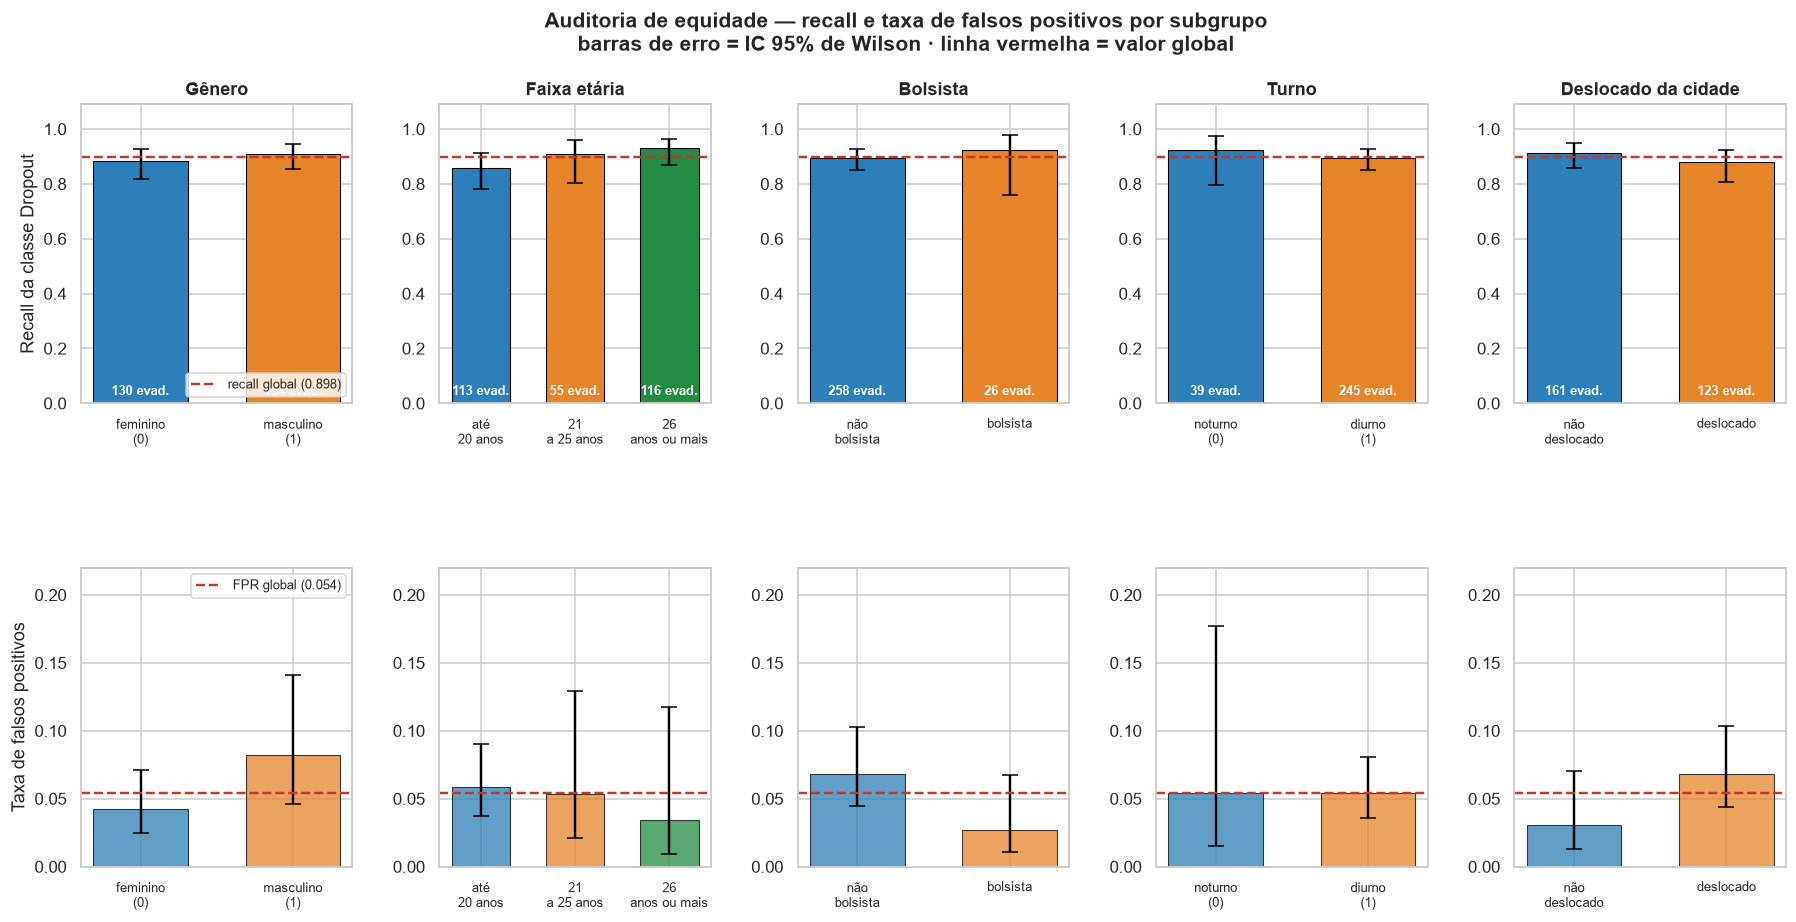

In [6]:
# --- Figura: recall e FPR por subgrupo -------------------------------------
n_var = len(SUBGRUPOS)
fig, eixos = plt.subplots(2, n_var, figsize=(4.0 * n_var, 9),
                          gridspec_kw={"hspace": 0.55, "wspace": 0.32})

recall_global = recall_score(y_teste, y_pred)
fpr_global = ((y_teste == 0) & (y_pred == 1)).sum() / (y_teste == 0).sum()
PALETA = ["#2c7fb8", "#e6842a", "#238b45"]

for col, (variavel, subs) in enumerate(SUBGRUPOS.items()):
    d = auditoria[auditoria["variável"] == variavel].reset_index(drop=True)
    rotulos = [s.replace(" ", "\n", 1) for s in d["subgrupo"]]
    x = np.arange(len(d))
    cores = PALETA[:len(d)]

    # linha 1 — recall
    ax = eixos[0, col]
    ax.bar(x, d["recall"], color=cores, edgecolor="black", linewidth=0.7, width=0.62)
    ax.errorbar(x, d["recall"],
                yerr=[d["recall"] - d["recall IC inf"], d["recall IC sup"] - d["recall"]],
                fmt="none", ecolor="black", capsize=5, linewidth=1.6)
    ax.axhline(recall_global, color="#c0392b", linestyle="--", linewidth=1.6)
    for xi, (v, nev) in enumerate(zip(d["recall"], d["evadidos"])):
        ax.text(xi, 0.03, f"{int(nev)} evad.", ha="center", fontsize=8.5, color="white",
                fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(rotulos, fontsize=8.8)
    ax.set_ylim(0, 1.09)
    ax.set_title(variavel, fontsize=11.5)
    if col == 0:
        ax.set_ylabel("Recall da classe Dropout")

    # linha 2 — FPR
    ax = eixos[1, col]
    ax.bar(x, d["FPR"], color=cores, edgecolor="black", linewidth=0.7, width=0.62, alpha=0.75)
    ax.errorbar(x, d["FPR"],
                yerr=[d["FPR"] - d["FPR IC inf"], d["FPR IC sup"] - d["FPR"]],
                fmt="none", ecolor="black", capsize=5, linewidth=1.6)
    ax.axhline(fpr_global, color="#c0392b", linestyle="--", linewidth=1.6)
    ax.set_xticks(x)
    ax.set_xticklabels(rotulos, fontsize=8.8)
    ax.set_ylim(0, 0.22)
    if col == 0:
        ax.set_ylabel("Taxa de falsos positivos")

eixos[0, 0].plot([], [], color="#c0392b", linestyle="--", linewidth=1.6,
                 label=f"recall global ({recall_global:.3f})")
eixos[0, 0].legend(fontsize=8.5, loc="lower right")
eixos[1, 0].plot([], [], color="#c0392b", linestyle="--", linewidth=1.6,
                 label=f"FPR global ({fpr_global:.3f})")
eixos[1, 0].legend(fontsize=8.5, loc="upper right")

fig.suptitle("Auditoria de equidade — recall e taxa de falsos positivos por subgrupo\n"
             "barras de erro = IC 95% de Wilson · linha vermelha = valor global",
             fontsize=14, fontweight="bold", y=0.975)
salvar("24_equidade_subgrupos.png")
plt.show()

In [7]:
# --- Persistência -----------------------------------------------------------
caminho = os.path.join(DIR_DADOS, "auditoria_equidade.csv")
auditoria.to_csv(caminho, index=False, encoding="utf-8")
print(f"[salvo] {caminho}  {auditoria.shape}")

caminho_resumo = os.path.join(DIR_DADOS, "auditoria_equidade_resumo.csv")
resumo.to_csv(caminho_resumo, index=False, encoding="utf-8")
print(f"[salvo] {caminho_resumo}  {resumo.shape}")

# --- Conferências -----------------------------------------------------------
verificacoes = {
    "partição reconstruída confere com y_test": list(y_bruto) == list(y_teste),
    "todos os alunos cobertos em cada variável":
        all(sum(int(m.sum()) for _, m in subs) == len(y_teste) for subs in SUBGRUPOS.values()),
    "nenhum subgrupo sem evadidos": bool((auditoria["evadidos"] > 0).all()),
    "recall global reproduzido": abs(recall_score(y_teste, y_pred) - 0.8979) < 1e-3,
}
print()
for descricao, ok in verificacoes.items():
    print(f"   [{'OK' if ok else 'FALHA'}] {descricao}")
assert all(verificacoes.values()), "Verificação falhou."

[salvo] dados\auditoria_equidade.csv  (11, 18)
[salvo] dados\auditoria_equidade_resumo.csv  (5, 8)

   [OK] partição reconstruída confere com y_test
   [OK] todos os alunos cobertos em cada variável
   [OK] nenhum subgrupo sem evadidos
   [OK] recall global reproduzido


## 4. Interpretação

### 4.1 Nenhuma disparidade significativa foi encontrada

Em nenhuma das cinco variáveis a diferença de recall entre subgrupos é estatisticamente significativa,
e **em nenhuma há par com intervalos de confiança disjuntos**. Todas as disparidades ficam **abaixo do
limite de 10 pontos percentuais** definido como critério de relevância.

Este é o resultado tranquilizador que **fortalece a recomendação de uso do modelo**: não há evidência de
que algum dos subgrupos examinados seja sistematicamente menos detectado.

### 4.2 A faixa etária é a que merece monitoramento

A maior disparidade está na **idade no ingresso**: 7,3 pontos percentuais de recall entre a faixa de 26
anos ou mais e a de até 20 anos, com **p = 0,072** — marginal, não significativa a 5%.

Dois detalhes fazem dela a candidata a monitoramento contínuo:

1. **A direção é monotônica.** O recall cresce consistentemente com a faixa: até 20 anos → 21–25 → 26+.
   Padrões monotônicos são menos compatíveis com ruído do que oscilações.
2. **Acompanha a taxa-base.** A evasão real também cresce com a idade (26,8% → 42,3% → 66,7%). O modelo
   detecta melhor onde a evasão é mais frequente — comportamento esperado de um classificador, e não
   sinal de viés contra um grupo específico.

**Implicação prática:** os alunos mais jovens são o grupo com maior risco de passarem sem alerta. Como
são também o grupo mais numeroso (422 de 726) e o de menor taxa de evasão, o efeito absoluto é
limitado — mas é o ponto a vigiar se o sistema entrar em operação.

### 4.3 Equalized odds: as taxas de falsos positivos também se sobrepõem

Paridade de recall sozinha não basta. Sob *equalized odds*, é preciso paridade simultânea de recall e de
FPR — caso contrário um grupo poderia ser "bem detectado" apenas por ser convocado em excesso.

Duas variáveis apresentam FPR relativamente diferente entre subgrupos:

| Variável | FPR menor | FPR maior | Razão |
|---|---|---|---|
| Gênero | feminino: 0,042 | masculino: 0,082 | ≈ 2× |
| Deslocado | não deslocado: 0,031 | deslocado: 0,068 | ≈ 2× |

Em termos **relativos** a diferença chama atenção; em termos **absolutos** é de 4 pontos percentuais, e
**os intervalos de confiança se sobrepõem em ambos os casos**. Homens e alunos deslocados são
convocados com mais frequência sem necessidade — mas dentro da margem de erro da amostra.

Vale notar que, para um sistema de **triagem para apoio**, um FPR mais alto significa *mais atenção
oferecida*, não uma penalidade. A assimetria de custo aqui é diferente da de um sistema de crédito ou
de justiça criminal, onde o falso positivo é punitivo.

### 4.4 A ressalva indispensável: esta auditoria tem poder estatístico limitado

Este é o ponto que impede a leitura de "está tudo bem".

O recall de cada subgrupo é calculado sobre os **evadidos daquele subgrupo**, e alguns grupos são
pequenos: **26 evadidos entre bolsistas**, **39 no turno noturno**. Nesses casos o intervalo de
confiança do recall tem 20 pontos percentuais de largura ou mais.

> **Uma disparidade real de 10 a 20 pontos percentuais em subgrupos pequenos seria indetectável com
> esta amostra.** A ausência de significância é **compatível** com equidade; não a comprova.
>
> Confundir "não detectei diferença" com "não há diferença" é o erro clássico de interpretação de teste
> de hipótese — e num contexto de alocação de apoio institucional, é um erro com consequências.

Por isso a conclusão desta auditoria não é "o modelo é justo", e sim: **não há evidência de injustiça
nos subgrupos e no tamanho de amostra examinados, e o monitoramento precisa continuar em operação.**

## 5. Consequências para as recomendações

### Ressalva a acrescentar à recomendação R-5

A R-5 do [doc 08](08-interpretabilidade-shap.md) propõe usar a explicação SHAP para encaminhar cada
aluno ao setor adequado. Ela ganha a seguinte ressalva:

> **R-5 (revisada).** O uso do modelo para alocação de recursos deve ser acompanhado de **monitoramento
> contínuo de equidade**. A auditoria não encontrou disparidade significativa entre gênero, faixa
> etária, condição de bolsista, turno e deslocamento — mas a amostra de teste (726 alunos, com
> subgrupos de até 26 evadidos) tem poder limitado para detectar disparidades moderadas.
>
> Em operação real, com volume acumulado maior, as mesmas métricas devem ser recalculadas
> periodicamente. O `08_auditoria_equidade.ipynb` é reexecutável para esse fim: basta apontá-lo para o
> novo conjunto de avaliação.
>
> **Ponto de atenção prioritário:** o recall dos **alunos mais jovens** (até 20 anos) é o menor da
> amostra (0,858 contra 0,931 dos alunos de 26 anos ou mais). A diferença não é significativa
> (p = 0,072), mas é a maior observada e tem direção consistente.

### Atualização da limitação L-11

| | |
|---|---|
| **Antes** | "Ausência de análise de equidade algorítmica" — registrada como a limitação mais importante entre as não previstas |
| **Depois** | **Parcialmente resolvida.** A auditoria foi executada em cinco atributos e não encontrou disparidade significativa. Permanece como limitação o **poder estatístico insuficiente** para subgrupos pequenos e a ausência de auditoria em atributos não examinados (nacionalidade, escolaridade dos pais, curso) |

## 6. Síntese

| Variável | Menor recall | Maior recall | Disparidade | p | Significativo |
|---|---|---|---:|---:|---|
| Faixa etária | até 20 anos: 0,858 | 26+ anos: 0,931 | **7,3 pp** | 0,0720 | não |
| Deslocado | deslocado: 0,878 | não deslocado: 0,913 | 3,5 pp | 0,3433 | não |
| Turno | diurno: 0,894 | noturno: 0,923 | 2,9 pp | 0,5343 | não |
| Bolsista | não bolsista: 0,895 | bolsista: 0,923 | 2,8 pp | 0,6181 | não |
| Gênero | feminino: 0,885 | masculino: 0,909 | 2,4 pp | 0,5008 | não |

| Verificação | Resultado |
|---|---|
| Disparidades acima de 10 pp | **nenhuma** |
| Disparidades estatisticamente significativas | **nenhuma** |
| Pares com ICs de recall disjuntos | **nenhum** |
| Maior disparidade | faixa etária, 7,3 pp (p = 0,072) |
| Disparidade de FPR mais alta | gênero e deslocamento, ≈ 4 pp (ICs sobrepostos) |
| Poder estatístico | **limitado** — subgrupos com 26 a 39 evadidos |

### As três afirmações que este notebook autoriza

1. **Não há evidência de disparidade** de recall ou de FPR entre gênero, faixa etária, condição de
   bolsista, turno e deslocamento, no conjunto de teste disponível.
2. **A faixa etária é o ponto de atenção**: alunos mais jovens têm o menor recall, com diferença
   marginal (p = 0,072) e direção monotônica que acompanha a taxa-base de evasão.
3. **A auditoria não comprova equidade** — apenas não encontra injustiça. O poder estatístico não
   permitiria detectar disparidades de 10 a 20 pp em subgrupos pequenos, e o monitoramento precisa
   continuar em operação.

### Decisão registrada

**D-40 · Manter o modelo, com monitoramento de equidade como condição de uso**

| | |
|---|---|
| **Alternativa rejeitada** | (a) Declarar o modelo "auditado e justo"; (b) remover gênero e variáveis socioeconômicas do modelo para evitar o problema |
| **Justificativa** | A auditoria não encontrou disparidade significativa, o que não justifica intervenção. Remover atributos sensíveis é ineficaz — o modelo os reconstrói por correlação — e reduziria a capacidade de detectar justamente os alunos socioeconomicamente vulneráveis. Mas o poder estatístico limitado impede declarar equidade |
| **Risco / limitação** | Disparidades de 10 a 20 pp em subgrupos pequenos permaneceriam indetectadas. Mitigado pela exigência de monitoramento contínuo (R-5 revisada) |
| **Onde** | `08_auditoria_equidade.ipynb` §4 |